# Price elasticity and pricing: what can 676 product-months tell us?

**Goal:** measure how much the units sold of a product change when its price changes (the **price elasticity of demand**) and see what that allows us to say about pricing decisions.

**Data:** `retail_price.csv`, the *Retail Price Optimization* case-study dataset (Kaggle): **52 products in 9 categories, 20 months (2017-01 to 2018-08), 676 product-month rows**. For each row: units sold (`qty`), average `unit_price`, freight price, competitor prices, product score, number of customers and calendar information (`holiday` and `weekday` count the holidays and weekdays of the month).

**What to expect:** with only 5 to 20 months per product and prices that were not set by an experiment, some questions can be answered and others cannot. The notebook says which is which.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

sns.set_theme(style="whitegrid")
df = pd.read_csv("data/retail_price.csv")
df["t"] = df["year"] * 12 + df["month"]                      # a single month counter
df["ln_q"], df["ln_p"] = np.log(df["qty"]), np.log(df["unit_price"])
df["rel_p"] = df["ln_p"] - np.log(df[["comp_1", "comp_2", "comp_3"]].mean(axis=1))   # own price relative to competitors
df = df.sort_values(["product_id", "t"]).reset_index(drop=True)
print("Rows, columns:", df.shape, "| products:", df.product_id.nunique(), "| categories:", df.product_category_name.nunique())
print("Missing values:", int(df.isna().sum().sum()), "| duplicated rows:", int(df.duplicated().sum()))
print("Months:", int(df.t.nunique()), "| rows per product (min / median / max):", df.groupby("product_id").size().agg(["min", "median", "max"]).astype(int).tolist())
df.head(3)

Rows, columns: (676, 34) | products: 52 | categories: 9
Missing values: 0 | duplicated rows: 0
Months: 20 | rows per product (min / median / max): [5, 13, 20]


,product_id,product_category_name,month_year,qty,total_price,freight_price,unit_price,product_name_lenght,product_description_lenght,product_photos_qty,...,ps2,fp2,comp_3,ps3,fp3,lag_price,t,ln_q,ln_p,rel_p
0,bed1,bed_bath_table,01-05-2017,1,45.95,15.100000,45.95,39,161,2,...,4.4,8.760000,45.95,4.0,15.100000,45.90,24209,0.000000,3.827554,-0.934193
1,bed1,bed_bath_table,01-06-2017,3,137.85,12.933333,45.95,39,161,2,...,4.4,21.322000,45.95,4.0,12.933333,45.95,24210,1.098612,3.827554,-0.916943
2,bed1,bed_bath_table,01-07-2017,6,275.70,14.840000,45.95,39,161,2,...,4.4,22.195932,45.95,4.0,14.840000,45.95,24211,1.791759,3.827554,-0.905276


## 1. Elasticity needs *variation*: does each product's price actually move?

To learn how demand reacts to price, the price of a product has to change over time. Products whose price never moves tell us nothing.

Products whose price barely moves (std of log price < 0.02): 6 of 52
Typical price movement inside a product (median std of log price): 0.078  ~ 8%


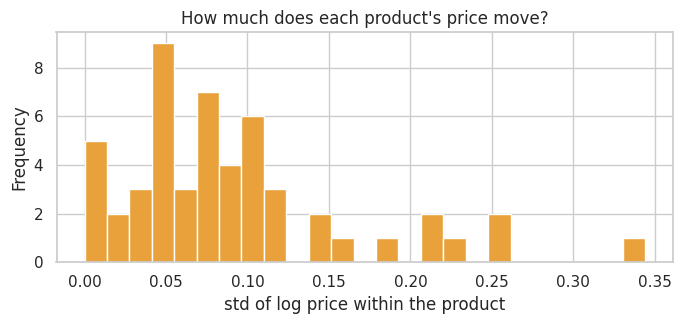

In [2]:
spread = df.groupby("product_id")["ln_p"].std().fillna(0)
print(f"Products whose price barely moves (std of log price < 0.02): {(spread < 0.02).sum()} of {len(spread)}")
print(f"Typical price movement inside a product (median std of log price): {spread.median():.3f}  ~ {spread.median():.0%}")
fig, ax = plt.subplots(figsize=(7, 3.4)); spread.plot.hist(bins=25, ax=ax, color="#e9a23b")
ax.set_xlabel("std of log price within the product"); ax.set_title("How much does each product's price move?"); plt.tight_layout(); plt.show()

## 2. The naive estimate is wrong, and the reason is instructive

If all rows are pooled, expensive products (few units, high price) and cheap products (many units, low price) are mixed together, and that comparison says nothing about what happens when *one* product changes its price.
The fix is to compare each product **with itself over time** (product fixed effects).

Naive pooled elasticity       : -0.13   (R-squared 0.01)
Within-product elasticity (FE): -2.44   95% CI [-3.23, -1.64]

Reading: a 1% price rise is associated with a 2.4% drop in units sold, for the same product.


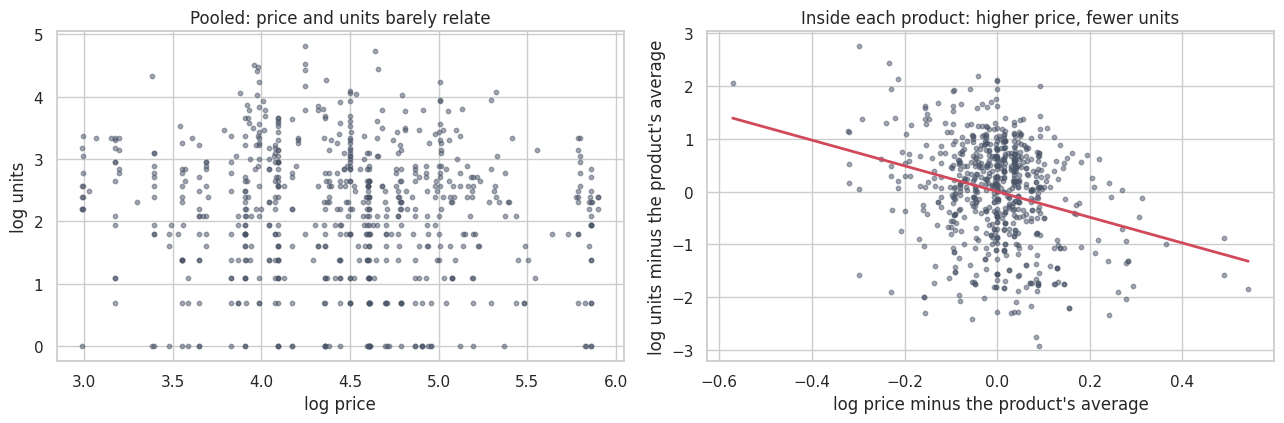

In [3]:
naive = smf.ols("ln_q ~ ln_p", df).fit()
fe    = smf.ols("ln_q ~ ln_p + C(product_id)", df).fit(cov_type="cluster", cov_kwds={"groups": df.product_id})
lo, hi = fe.conf_int().loc["ln_p"]
print(f"Naive pooled elasticity       : {naive.params['ln_p']:+.2f}   (R-squared {naive.rsquared:.2f})")
print(f"Within-product elasticity (FE): {fe.params['ln_p']:+.2f}   95% CI [{lo:+.2f}, {hi:+.2f}]")
print(f"\nReading: a 1% price rise is associated with a {abs(fe.params['ln_p']):.1f}% drop in units sold, for the same product.")

# the picture: raw cloud vs the same data after removing each product's own average
d = df.copy()
d["ln_p_dm"] = d.ln_p - d.groupby("product_id").ln_p.transform("mean")
d["ln_q_dm"] = d.ln_q - d.groupby("product_id").ln_q.transform("mean")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
axes[0].scatter(d.ln_p, d.ln_q, s=10, alpha=.5, color="#4a5568"); axes[0].set_title("Pooled: price and units barely relate"); axes[0].set_xlabel("log price"); axes[0].set_ylabel("log units")
axes[1].scatter(d.ln_p_dm, d.ln_q_dm, s=10, alpha=.5, color="#4a5568")
xs = np.linspace(d.ln_p_dm.min(), d.ln_p_dm.max(), 50); axes[1].plot(xs, fe.params["ln_p"] * xs, color="#d1495b", lw=2)
axes[1].set_title("Inside each product: higher price, fewer units"); axes[1].set_xlabel("log price minus the product's average"); axes[1].set_ylabel("log units minus the product's average")
plt.tight_layout(); plt.show()

## 3. Is that number robust?

Prices and sales move with the season, with competitors and with the product's score, so we check that the estimate does not depend on one particular specification.

In [4]:
specs = {
    "Product fixed effects only":                                   "ln_q ~ ln_p + C(product_id)",
    "+ month, holidays and product score":                          "ln_q ~ ln_p + C(product_id) + C(month) + holiday + product_score",
    "+ month-by-month effects and price relative to competitors":   "ln_q ~ ln_p + C(product_id) + C(t) + rel_p",
}
rows = []
for name, f in specs.items():
    m = smf.ols(f, df).fit(cov_type="cluster", cov_kwds={"groups": df.product_id}); lo, hi = m.conf_int().loc["ln_p"]
    rows.append({"specification": name, "elasticity": m.params["ln_p"], "CI low": lo, "CI high": hi, "p-value": m.pvalues["ln_p"]})
robust = pd.DataFrame(rows).set_index("specification"); display(robust.round(2))

/tmp/ipykernel_243/835792212.py:8: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m = smf.ols(f, df).fit(cov_type="cluster", cov_kwds={"groups": df.product_id}); lo, hi = m.conf_int().loc["ln_p"]


,elasticity,CI low,CI high,p-value
specification,,,,
Product fixed effects only,-2.44,-3.23,-1.64,0.0
"+ month, holidays and product score",-2.57,-3.37,-1.77,0.0
+ month-by-month effects and price relative to competitors,-2.61,-3.62,-1.59,0.0


The estimate stays around **-2.4 to -2.6** whatever we control for: demand is **elastic** (a larger change in units than in price). Standard errors are clustered by product, since the months of one product are not independent.

## 4. By category

,products,rows,elasticity,lo,hi
category,,,,,
perfumery,2,26,-7.20,-18.70,4.29
furniture_decor,4,48,-7.06,-9.22,-4.90
bed_bath_table,5,61,-3.88,-11.04,3.27
consoles_games,2,22,-2.69,-7.74,2.35
computers_accessories,6,69,-2.67,-5.93,0.60
watches_gifts,8,103,-2.51,-3.53,-1.48
cool_stuff,5,57,-1.71,-6.10,2.68
garden_tools,10,160,-1.12,-3.11,0.88
health_beauty,10,130,0.65,-4.91,6.21


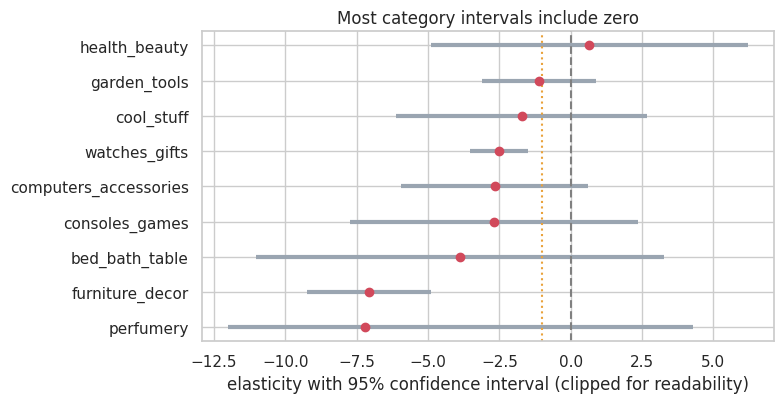

Categories whose interval excludes zero: 2 of 9


In [5]:
rows = []
for cat, g in df.groupby("product_category_name"):
    m = smf.ols("ln_q ~ ln_p + C(product_id) + C(month)", g).fit(cov_type="cluster", cov_kwds={"groups": g.product_id}); lo, hi = m.conf_int().loc["ln_p"]
    rows.append({"category": cat, "products": g.product_id.nunique(), "rows": len(g), "elasticity": m.params["ln_p"], "lo": lo, "hi": hi})
cat = pd.DataFrame(rows).set_index("category").sort_values("elasticity")
display(cat.round(2))
fig, ax = plt.subplots(figsize=(8, 4.2))
ypos = np.arange(len(cat)); ax.hlines(ypos, cat.lo.clip(lower=-12), cat.hi.clip(upper=8), color="#9aa5b1", lw=3); ax.scatter(cat.elasticity, ypos, color="#d1495b", zorder=3)
ax.axvline(0, color="grey", ls="--"); ax.axvline(-1, color="#e9a23b", ls=":"); ax.set_yticks(ypos); ax.set_yticklabels(cat.index)
ax.set_xlabel("elasticity with 95% confidence interval (clipped for readability)"); ax.set_title("Most category intervals include zero"); plt.tight_layout(); plt.show()
n_sig = int(((cat.lo > 0) | (cat.hi < 0)).sum()); print(f"Categories whose interval excludes zero: {n_sig} of {len(cat)}")

## 5. By product: how reliable is each individual estimate?

Products with enough price variation and at least 8 months: 42 of 52
  negative estimate: 30 | statistically significant (p<0.05): 12 | significant and negative: 9 | significant and POSITIVE: 3
  median width of the 95% interval: 11.8 elasticity points


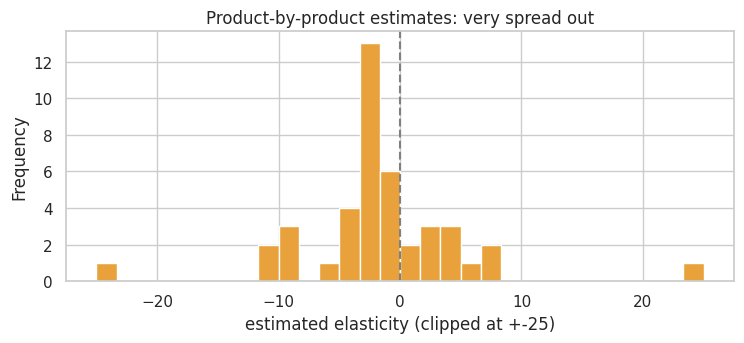

In [6]:
rows = []
for p, g in df.groupby("product_id"):
    if g.ln_p.std() < 0.02 or len(g) < 8:
        continue
    m = smf.ols("ln_q ~ ln_p", g).fit(); lo, hi = m.conf_int().loc["ln_p"]
    rows.append({"product": p, "category": g.product_category_name.iloc[0], "months": len(g), "elasticity": m.params["ln_p"], "se": m.bse["ln_p"], "lo": lo, "hi": hi, "p": m.pvalues["ln_p"]})
prod = pd.DataFrame(rows).set_index("product")
sig = prod.p < 0.05
print(f"Products with enough price variation and at least 8 months: {len(prod)} of {df.product_id.nunique()}")
print(f"  negative estimate: {(prod.elasticity < 0).sum()} | statistically significant (p<0.05): {sig.sum()} | significant and negative: {(sig & (prod.elasticity < 0)).sum()} | significant and POSITIVE: {(sig & (prod.elasticity > 0)).sum()}")
print(f"  median width of the 95% interval: {(prod.hi - prod.lo).median():.1f} elasticity points")
fig, ax = plt.subplots(figsize=(7.6, 3.6)); prod.elasticity.clip(-25, 25).plot.hist(bins=30, ax=ax, color="#e9a23b"); ax.axvline(0, color="grey", ls="--")
ax.set_title("Product-by-product estimates: very spread out"); ax.set_xlabel("estimated elasticity (clipped at +-25)"); plt.tight_layout(); plt.show()

Product-by-product estimates are **very noisy**: the typical 95% interval is about 12 points wide, and some significant results have the *wrong sign* (a price rise followed by more sales), which is the fingerprint of other things moving at the same time.

Is there anything real behind the differences, or is it all noise? A **heterogeneity test** answers that, and a **partial-pooling (shrinkage)** step pulls the noisiest estimates toward the common value.

Heterogeneity across the 42 products: Q = 156 (df 41), p = 0.0000, I-squared = 74%, between-product std = 3.6
Average elasticity, accounting for that heterogeneity: -1.82   95% CI [-3.23, -0.41]
Raw estimates range -29.8 to 25.6; after shrinkage -8.8 to 7.0


,category,elasticity,se,elasticity_shrunk
product,,,,
bed4,bed_bath_table,-29.8,6.4,-8.6
perfumery2,perfumery,-10.5,1.8,-8.8
furniture2,furniture_decor,-10.2,2.2,-7.9
bed1,bed_bath_table,-9.9,2.0,-7.9


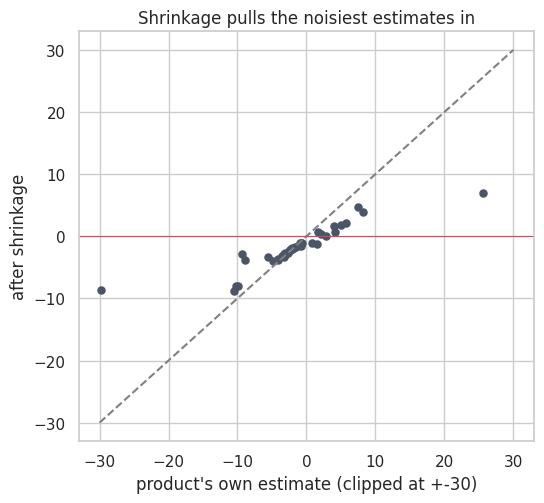

In [7]:
from scipy import stats
k, w = len(prod), 1 / prod["se"] ** 2
mu_fe = (w * prod.elasticity).sum() / w.sum()
Q = (w * (prod.elasticity - mu_fe) ** 2).sum()
tau2 = max(0, (Q - (k - 1)) / (w.sum() - (w ** 2).sum() / w.sum()))      # DerSimonian-Laird between-product variance
I2 = max(0, (Q - (k - 1)) / Q)
w_re = 1 / (prod["se"] ** 2 + tau2)
mu_re, se_re = (w_re * prod.elasticity).sum() / w_re.sum(), np.sqrt(1 / w_re.sum())
prod["shrink_weight"] = tau2 / (tau2 + prod["se"] ** 2)
prod["elasticity_shrunk"] = mu_re + prod["shrink_weight"] * (prod.elasticity - mu_re)

print(f"Heterogeneity across the {k} products: Q = {Q:.0f} (df {k-1}), p = {1 - stats.chi2.cdf(Q, k - 1):.4f}, I-squared = {I2:.0%}, between-product std = {np.sqrt(tau2):.1f}")
print(f"Average elasticity, accounting for that heterogeneity: {mu_re:+.2f}   95% CI [{mu_re - 1.96 * se_re:+.2f}, {mu_re + 1.96 * se_re:+.2f}]")
print(f"Raw estimates range {prod.elasticity.min():.1f} to {prod.elasticity.max():.1f}; after shrinkage {prod.elasticity_shrunk.min():.1f} to {prod.elasticity_shrunk.max():.1f}")
worst = prod.reindex(prod.elasticity.sort_values().index[:4])[["category", "elasticity", "se", "elasticity_shrunk"]]
display(worst.round(1))
fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.scatter(prod.elasticity.clip(-30, 30), prod.elasticity_shrunk, s=26, color="#4a5568"); ax.plot([-30, 30], [-30, 30], "--", color="grey")
ax.axhline(0, color="#d1495b", lw=.8); ax.set_xlabel("product's own estimate (clipped at +-30)"); ax.set_ylabel("after shrinkage"); ax.set_title("Shrinkage pulls the noisiest estimates in")
plt.tight_layout(); plt.show()

The differences between products are **real** (I-squared is about 74%: most of the spread is more than sampling noise), but each product's own number is too imprecise to rely on. Even after shrinkage the extremes stay large and some are still positive, which points to other factors (promotions, stock-outs, competitor moves) moving together with the price. **Product-level elasticities should be read as hypotheses, not as measurements.**

## 6. Does knowing the price help predict future sales?

A model can have a significant coefficient and still be useless for prediction. We train on the first 80% of the months and predict the last 20%.

In [8]:
cut = df.t.quantile(0.8)
train, test = df[df.t <= cut], df[df.t > cut]
test = test[test.product_id.isin(train.product_id)]
mae = lambda a, b: float(np.mean(np.abs(a - b)))
out = {
    "Each product's average (no price)":                  test.product_id.map(train.groupby("product_id").ln_q.mean()),
    "Each product's last month (naive)":                  test.product_id.map(train.groupby("product_id").ln_q.last()),
    "Product average + price (fixed-effects model)":      smf.ols("ln_q ~ ln_p + C(product_id)", train).fit().predict(test),
    "Product average + price + month of the year":        smf.ols("ln_q ~ ln_p + C(product_id) + C(month)", train).fit().predict(test),
}
res = pd.DataFrame({"MAE (log units)": {k: mae(test.ln_q, v) for k, v in out.items()}}).sort_values("MAE (log units)")
print(f"Train: up to month index {int(cut)} ({len(train)} rows) | Test: later months ({len(test)} rows)")
display(res.round(3))

Train: up to month index 24221 (556 rows) | Test: later months (120 rows)


,MAE (log units)
Product average + price + month of the year,0.954
Each product's average (no price),0.956
Product average + price (fixed-effects model),1.024
Each product's last month (naive),1.035


Adding the price brings **no real improvement**: the model with price and month of the year (0.954) ties with each product's own average (0.956), and the model with the price alone is worse (1.024). The price effect is real *within* a product over the whole period, but with this little data it does not improve next-month forecasts. The test set is small (about 120 rows), so this is a warning, not a verdict.

## 7. From elasticity to pricing: what can and cannot be said

With a constant elasticity *e*, a price change of Δ changes revenue by `(1 + Δ)^(1 + e) - 1`. For an elastic product (*e* < -1), **lowering** the price raises revenue and raising it lowers revenue.

In [9]:
e_hat = fe.params["ln_p"]; e_lo, e_hi = fe.conf_int().loc["ln_p"]
eff = lambda e, delta: (1 + delta) ** (1 + e) - 1
rows = []
for delta in (-0.10, -0.05, +0.05, +0.10):
    a, b = sorted([eff(e_lo, delta), eff(e_hi, delta)])
    rows.append({"price change": f"{delta:+.0%}", "revenue change (best estimate)": f"{eff(e_hat, delta):+.1%}", "range (95% CI of the elasticity)": f"{a:+.1%} to {b:+.1%}"})
display(pd.DataFrame(rows).set_index("price change"))

,revenue change (best estimate),range (95% CI of the elasticity)
price change,,
-10%,+16.3%,+7.0% to +26.5%
-5%,+7.6%,+3.3% to +12.1%
+5%,-6.8%,-10.3% to -3.1%
+10%,-12.8%,-19.1% to -5.9%


**What this does *not* give us:** an optimal price. Revenue is not profit: the data has **no unit cost**, only freight price. A price cut that raises revenue can still lower profit.
For a constant elasticity *e* < -1, theory says the profit-maximising price is `p* = c * e / (1 + e)` where `c` is the unit cost, i.e. a markup of `1 / (|e| - 1)` over cost. With *e* = -2.5 that is a markup of about 67% over cost: the formula needs the cost, which is exactly what is missing here.

**What it does give us:** an order of magnitude. If the average elasticity were causal, a 10% price cut would go with roughly **+7% to +27%** more revenue, and a 10% rise with **-6% to -19%**. At product level the estimates are too uncertain to recommend a price, so the next step is a controlled price experiment on a few products, not a price list.

## 8. Conclusions

- **Demand is elastic.** Inside the same product, a 1% higher price goes with about **2.4-2.6% fewer units** (95% interval roughly -3.2 to -1.6), and this holds across three specifications.
- **The naive number is misleading.** Pooling all products gives -0.13 (almost no relation) because expensive and cheap products are being compared with each other. Fixed effects fix this.
- **Products really differ, but each estimate is imprecise.** The heterogeneity test is clear (I-squared about 74%), yet the typical 95% interval of a product is ~12 points wide, 3 of the 12 significant products have the wrong sign, and only 2 of 9 category intervals exclude zero. Product-level numbers are hypotheses, not measurements.
- **The price does not improve out-of-sample predictions:** the best model with price (0.954) ties with each product's own average (0.956) on a test of ~120 rows.
- **No optimal price can be computed** without unit costs. As an order of magnitude, if the average elasticity were causal, a 10% price cut would go with +7% to +27% revenue; that is a reason to run a test, not a price recommendation.

**Limitations**

- Prices were not randomised: they moved with promotions, competitors and seasons, so the elasticity may be biased. Competitor prices and month effects reduce but do not remove this.
- 5 to 20 months per product is little, and a constant elasticity is a simplification.
- Customers is not used as a control, because it is itself an outcome of price.

**Next steps:** a price experiment (A/B test) on a few products, unit-cost data to compute profit, and a full hierarchical Bayesian model instead of the simple shrinkage used here.